In [ ]:
import numpy as np
import torch
from torch import nn
from torch import optim
import torch.nn.functional as F
from PIL import Image
import torchvision.transforms as transforms
from matplotlib import pyplot as plt


In [ ]:
import random

def get_random_number(h,w,nb):
  list = []
  for i in range(nb):
    hindex = random.randint(0, h)
    windex = random.randint(0,w)
    list.append((hindex,windex))
  return list
print(get_random_number(10,20,10))

[(4, 14), (6, 6), (3, 15), (3, 5), (6, 4), (3, 17), (0, 7), (0, 20), (7, 15), (8, 19)]


In [ ]:

class MyUNet(nn.Module): #hérite de nn.Module
    def __init__(self):
        super(MyUNet, self).__init__()

        self.conv1 = nn.Conv2d(16, 32, 4,2,1)
        self.bn1 = nn.BatchNorm2d(32)

        self.conv2 = nn.Conv2d(32, 64, 4,2,1)
        self.bn2 = nn.BatchNorm2d(64)

        self.conv3 = nn.Conv2d(64, 128, 4,2,1)
        self.bn3 = nn.BatchNorm2d(128)

        self.conv4 = nn.Conv2d(128, 256, 4,2,1)
        self.bn4 = nn.BatchNorm2d(256)

        self.conv5 = nn.ConvTranspose2d(256,128,4,2,padding=1)
        self.bn5 = nn.BatchNorm2d(128)

        self.conv6 = nn.ConvTranspose2d(128,64,4,2,padding=1)
        self.bn6 = nn.BatchNorm2d(64)

        self.conv7 = nn.ConvTranspose2d(64,32,4,2,padding=1)
        self.bn7 = nn.BatchNorm2d(32)

        self.conv8 = nn.ConvTranspose2d(32,3,4,2,padding=1)
        self.bn8 = nn.BatchNorm2d(3)

        self.skip1 = nn.Conv2d(128,128,5,1,padding="same")
        self.skip2 = nn.Conv2d(64,64,4,1,padding="same")

    def forward(self,x):
        print(x.shape)

        x = F.leaky_relu(self.bn1(self.conv1(x)))
        print(x.shape)

        x = F.leaky_relu(self.bn2(self.conv2(x)))
        print(x.shape)

        s2 = F.leaky_relu(self.skip2(x))

        x = F.leaky_relu(self.bn3(self.conv3(x)))
        print(x.shape)

        s1 = F.leaky_relu(self.skip1(x))

        x = F.leaky_relu(self.bn4(self.conv4(x)))
        print(x.shape)

        x = F.leaky_relu(self.bn5(self.conv5(x)))



        x = F.leaky_relu(self.bn6(self.conv6(x)))

       # x = torch.cat([x,s2],dim=1)
        print(x.shape)

        x = F.leaky_relu(self.bn7(self.conv7(x)))
        print(x.shape)

        x = F.sigmoid(self.bn8(self.conv8(x)))

        return x


In [ ]:

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

myunet = MyUNet()
myunet.to(device)


input_img = Image.open('testcrop.jpg')
transform = transforms.Compose([transforms.PILToTensor()])
target = transform(input_img)/255
target = target.unsqueeze(0).float().to(device)
h = target.size()[2]
w = target.size()[3]
indexs_to_masq=get_random_number(h-1,w-1,100)
#print(indexs_to_masq)

print(target.shape)
for i in range (3):
  for index in indexs_to_masq:
    target[0,i,index[0],index[1]]=0
count = (target == 0).sum().item()
print(count)
z = torch.rand(1,16, h, w).to(device)
print(h)


#Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(myunet.parameters(), lr=0.001,momentum=0.9)
losslog = []

torch.Size([1, 3, 160, 256])
384
160


In [ ]:
for i in range(0,2000):
  output=myunet(z)
  loss=criterion(output,target)
  loss.backward()
  optimizer.step()

Le flux de sortie a été tronqué et ne contient que les 5000 dernières lignes.
torch.Size([1, 64, 40, 64])
torch.Size([1, 32, 80, 128])
torch.Size([1, 16, 160, 256])
torch.Size([1, 32, 80, 128])
torch.Size([1, 64, 40, 64])
torch.Size([1, 128, 20, 32])
torch.Size([1, 256, 10, 16])
torch.Size([1, 64, 40, 64])
torch.Size([1, 32, 80, 128])
torch.Size([1, 16, 160, 256])
torch.Size([1, 32, 80, 128])
torch.Size([1, 64, 40, 64])
torch.Size([1, 128, 20, 32])
torch.Size([1, 256, 10, 16])
torch.Size([1, 64, 40, 64])
torch.Size([1, 32, 80, 128])
torch.Size([1, 16, 160, 256])
torch.Size([1, 32, 80, 128])
torch.Size([1, 64, 40, 64])
torch.Size([1, 128, 20, 32])
torch.Size([1, 256, 10, 16])
torch.Size([1, 64, 40, 64])
torch.Size([1, 32, 80, 128])
torch.Size([1, 16, 160, 256])
torch.Size([1, 32, 80, 128])
torch.Size([1, 64, 40, 64])
torch.Size([1, 128, 20, 32])
torch.Size([1, 256, 10, 16])
torch.Size([1, 64, 40, 64])
torch.Size([1, 32, 80, 128])
torch.Size([1, 16, 160, 256])
torch.Size([1, 32, 80, 128]

In [ ]:

output = myunet(z)

plt.imsave('fil3.jpg', output[0].cpu().detach().permute(1,2,0).numpy())


torch.Size([1, 16, 160, 256])
torch.Size([1, 32, 80, 128])
torch.Size([1, 64, 40, 64])
torch.Size([1, 128, 20, 32])
torch.Size([1, 256, 10, 16])
torch.Size([1, 64, 40, 64])
torch.Size([1, 32, 80, 128])


tensor(1.0716, grad_fn=<DivBackward1>)


IndexError: list index out of range

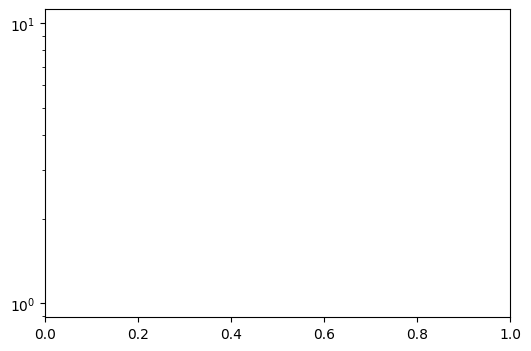

In [ ]:
plt.figure(figsize=(6,4))
#print(output)
plt.yscale('log')
print(loss)
plt.plot(losslog, label = 'loss ({:.4f})'.format(losslog[-1]))
plt.xlabel("Epochs")
plt.legend()
plt.show()
plt.close()


In [ ]:
print(output[0])

In [ ]:
mask = torch.ones(
    target.shape[2:], dtype=torch.bool, device=target.device
)
print(mask)